# Load Data

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv(r"C:\Users\BBUNCH01\Documents\ml-project\data\AmesHousing.csv")
df = df.drop(columns=["Order", "PID"])

df.columns

Index(['MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street',
       'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config',
       'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type',
       'House Style', 'Overall Qual', 'Overall Cond', 'Year Built',
       'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st',
       'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2',
       'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air',
       'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
       'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath',
       'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual',
       'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu',
       'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Gara

# Shape and Types

In [98]:
print(f"Shape: {df.shape}")
df.dtypes.value_counts()

Shape: (2930, 80)


str        43
int64      26
float64    11
Name: count, dtype: int64

In [99]:
df["MS SubClass"] = df["MS SubClass"].astype(str)
df["Mo Sold"] = df["Mo Sold"].astype(str)

In [100]:
num_cols = df.select_dtypes("number").columns.drop("SalePrice")
cat_cols = df.select_dtypes(exclude="number").columns

# Target Column

In [101]:
df["SalePrice"].describe()

count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64

<Axes: xlabel='SalePrice', ylabel='Count'>

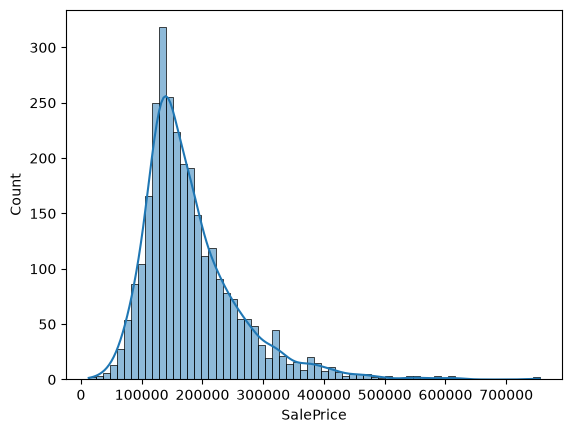

In [102]:
sns.histplot(df["SalePrice"], kde=True)

<Axes: xlabel='SalePrice', ylabel='Count'>

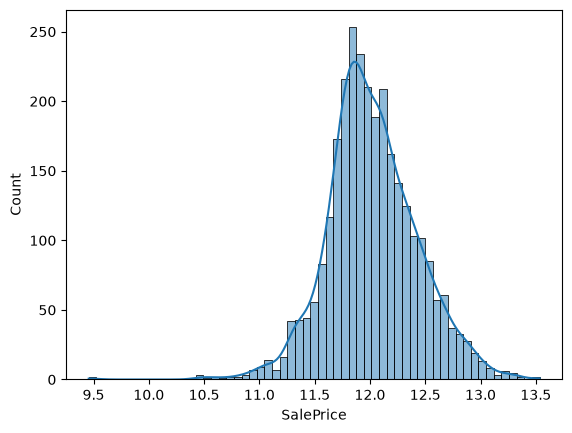

In [103]:
sns.histplot(np.log1p(df["SalePrice"]), kde=True)

In [104]:
df['SalePrice'].skew(), np.log1p(df['SalePrice']).skew()

(np.float64(1.7435000757376466), np.float64(-0.014772659537224368))

skew 1.74 to -0.01 after log1p. Model Log Price

# Missing Values

In [105]:
miss = df.isna().mean().sort_values(ascending=False)
miss[miss>0]

Pool QC           0.995563
Misc Feature      0.963823
Alley             0.932423
Fence             0.804778
Mas Vnr Type      0.605802
Fireplace Qu      0.485324
Lot Frontage      0.167235
Garage Yr Blt     0.054266
Garage Qual       0.054266
Garage Cond       0.054266
Garage Finish     0.054266
Garage Type       0.053584
Bsmt Exposure     0.028328
BsmtFin Type 2    0.027645
Bsmt Qual         0.027304
BsmtFin Type 1    0.027304
Bsmt Cond         0.027304
Mas Vnr Area      0.007850
Bsmt Full Bath    0.000683
Bsmt Half Bath    0.000683
BsmtFin SF 2      0.000341
Garage Area       0.000341
Total Bsmt SF     0.000341
BsmtFin SF 1      0.000341
Electrical        0.000341
Bsmt Unf SF       0.000341
Garage Cars       0.000341
dtype: float64

In [106]:
none_cols = ["Pool QC", "Misc Feature", "Alley", "Fence", "Fireplace Qu", "Mas Vnr Type",
             "Garage Type", "Garage Finish", "Garage Qual", "Garage Cond",
             "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2"]
df[none_cols] = df[none_cols].fillna("None")

In [107]:
zero_cols = ["Total Bsmt SF", "BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF",
             "Bsmt Full Bath", "Bsmt Half Bath", "Garage Area", "Garage Cars", "Mas Vnr Area"]
df[zero_cols] = df[zero_cols].fillna(0)

In [ ]:
df["has_garage"] = (df["Garage Type"] != "None").astype(int)
df["Garage Yr Blt"] = df["Garage Yr Blt"].fillna(df["Year Built"])

In [114]:
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])
df["Lot Frontage"] = df.groupby("Neighborhood")["Lot Frontage"].transform(lambda s: s.fillna(s.median()))
df["Lot Frontage"] = df["Lot Frontage"].fillna(df["Lot Frontage"].median())

In [115]:
df.isna().sum().sum()

np.int64(0)

# Numeric univariate

Year Built         -0.604462
Garage Yr Blt      -0.463698
Year Remod/Add     -0.451863
Garage Cars        -0.221163
Yr Sold             0.134862
Full Bath           0.171952
Overall Qual        0.190634
Garage Area         0.240065
Bedroom AbvGr       0.305694
Overall Cond        0.574429
Bsmt Full Bath      0.617728
Half Bath           0.697713
Fireplaces          0.739215
TotRms AbvGrd       0.753543
2nd Flr SF          0.866457
Bsmt Unf SF         0.923045
Total Bsmt SF       1.150846
Gr Liv Area         1.274110
BsmtFin SF 1        1.416421
1st Flr SF          1.469429
Lot Frontage        1.500791
Wood Deck SF        1.842678
Open Porch SF       2.535386
Mas Vnr Area        2.619305
Bsmt Half Bath      3.942389
Screen Porch        3.957467
Enclosed Porch      4.014446
BsmtFin SF 2        4.140794
Kitchen AbvGr       4.313825
3Ssn Porch         11.403795
Low Qual Fin SF    12.118162
Lot Area           12.820898
Pool Area          16.939142
Misc Val           21.999788
dtype: float64

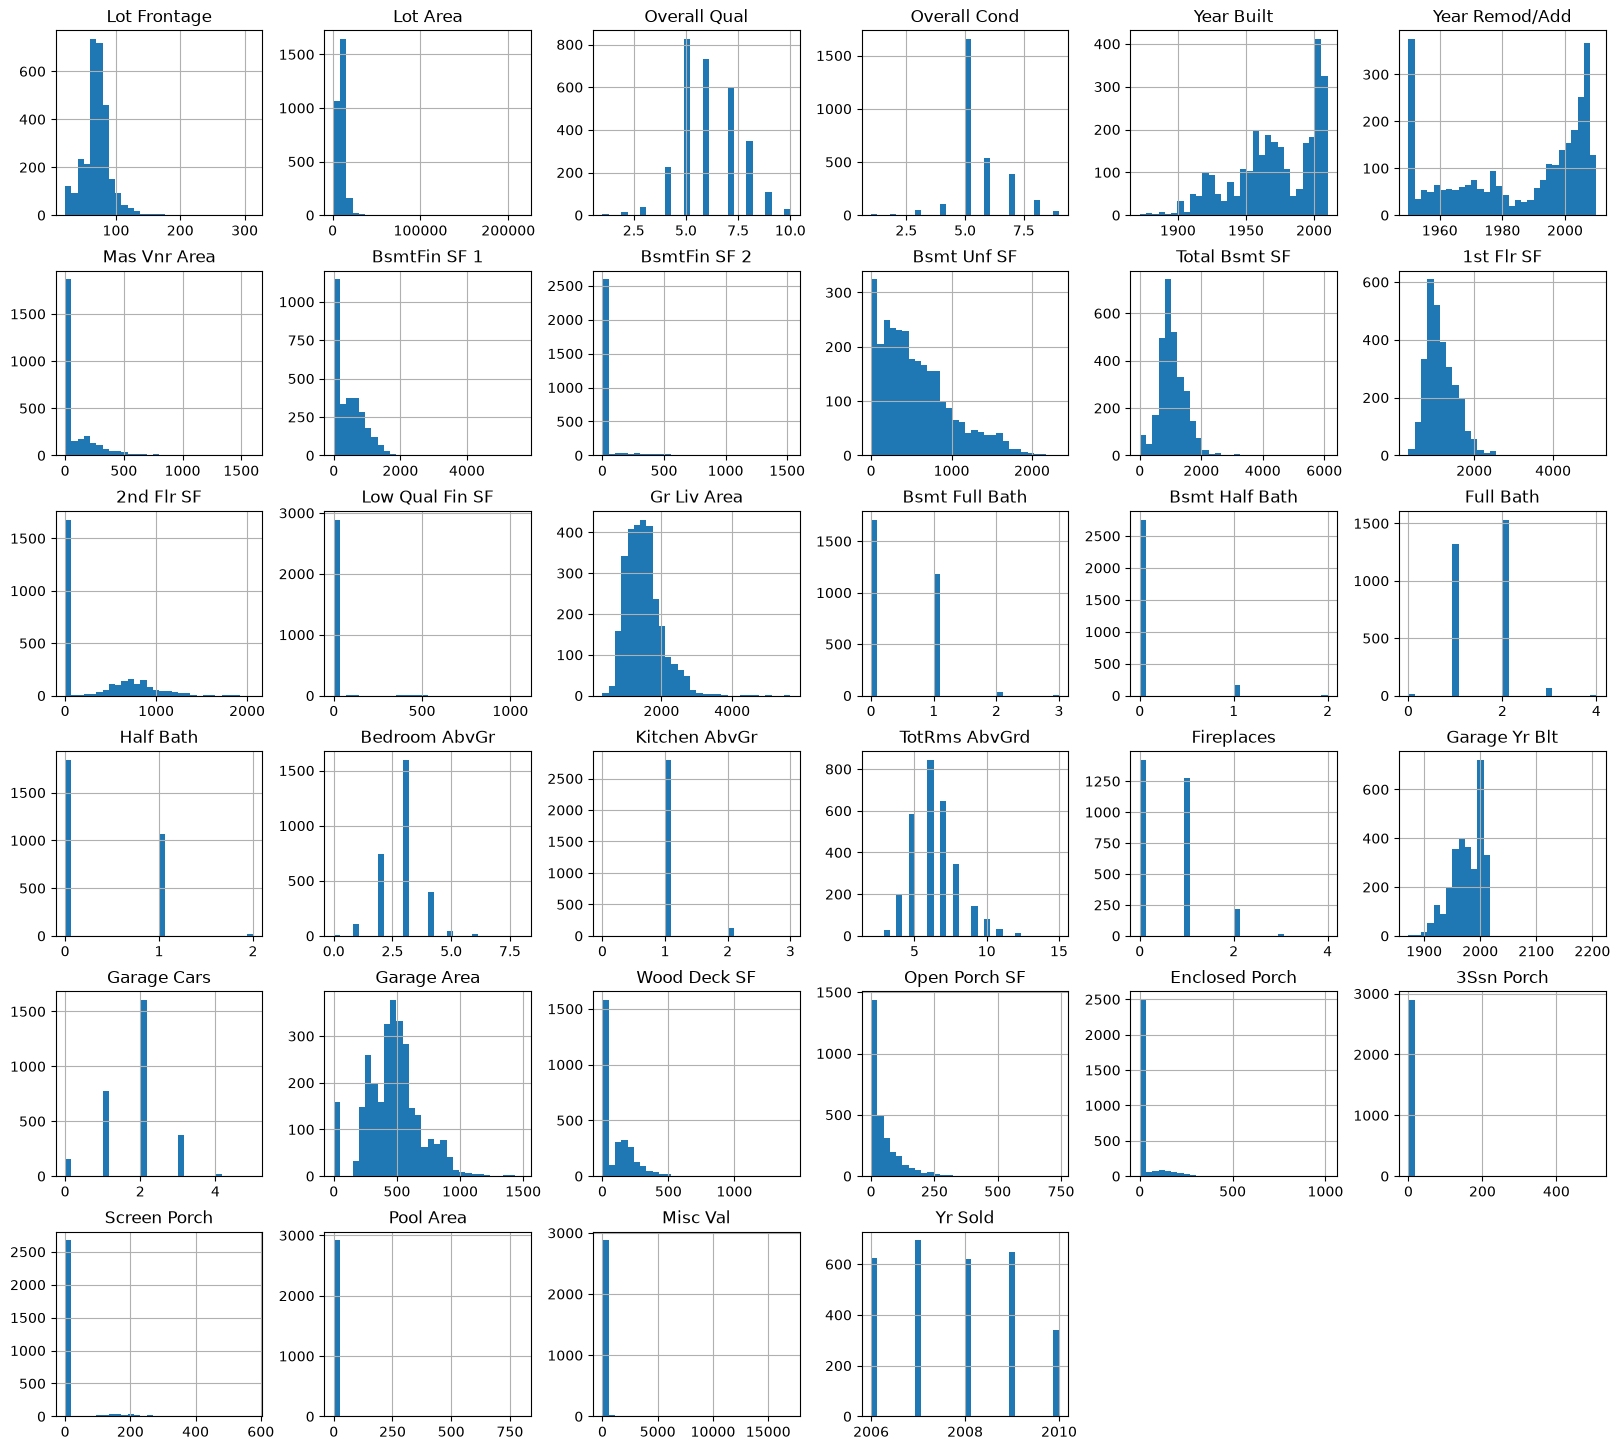

In [116]:
df[num_cols].describe().T
df[num_cols].hist(bins=30, figsize=(20, 18))
df[num_cols].skew().sort_values()

# Categorical univariate

In [117]:
for c in cat_cols:
    print(df[c].value_counts(dropna=False).head(), "\n")

MS SubClass
20     1079
60      575
50      287
120     192
30      139
Name: count, dtype: int64 

MS Zoning
RL         2273
RM          462
FV          139
RH           27
C (all)      25
Name: count, dtype: int64 

Street
Pave    2918
Grvl      12
Name: count, dtype: int64 

Alley
None    2732
Grvl     120
Pave      78
Name: count, dtype: int64 

Lot Shape
Reg    1859
IR1     979
IR2      76
IR3      16
Name: count, dtype: int64 

Land Contour
Lvl    2633
HLS     120
Bnk     117
Low      60
Name: count, dtype: int64 

Utilities
AllPub    2927
NoSewr       2
NoSeWa       1
Name: count, dtype: int64 

Lot Config
Inside     2140
Corner      511
CulDSac     180
FR2          85
FR3          14
Name: count, dtype: int64 

Land Slope
Gtl    2789
Mod     125
Sev      16
Name: count, dtype: int64 

Neighborhood
NAmes      443
CollgCr    267
OldTown    239
Edwards    194
Somerst    182
Name: count, dtype: int64 

Condition 1
Norm      2522
Feedr      164
Artery      92
RRAn        50
PosN    

# Feature vs Target

In [138]:
df = df.drop(index=[1498, 2180, 2181]).reset_index(drop=True)
corr = df[num_cols.tolist() + ["SalePrice"]].corr(method="spearman")["SalePrice"]
corr.drop("SalePrice").abs().sort_values(ascending=False).head(15)

Overall Qual      0.809573
Gr Liv Area       0.723940
Garage Cars       0.701777
Year Built        0.681289
Garage Area       0.661002
Garage Yr Blt     0.649098
Full Bath         0.634253
Total Bsmt SF     0.607050
Year Remod/Add    0.601819
1st Flr SF        0.581979
Fireplaces        0.526498
TotRms AbvGrd     0.499542
Open Porch SF     0.479787
Mas Vnr Area      0.435069
Lot Area          0.429438
Name: SalePrice, dtype: float64

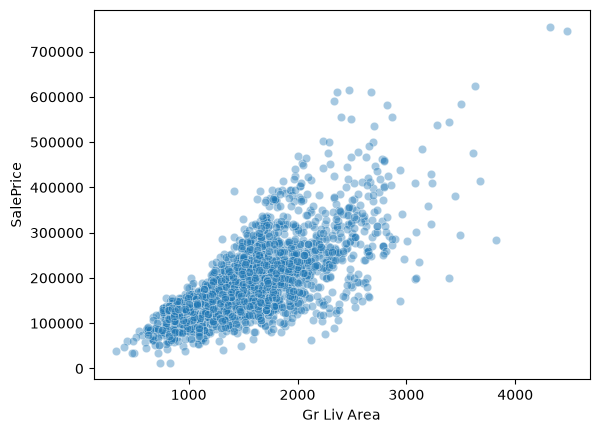

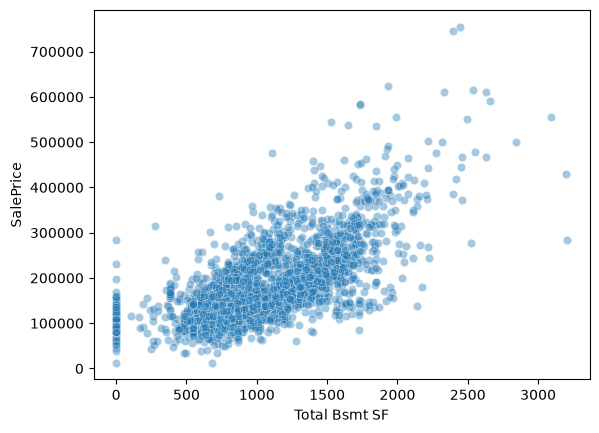

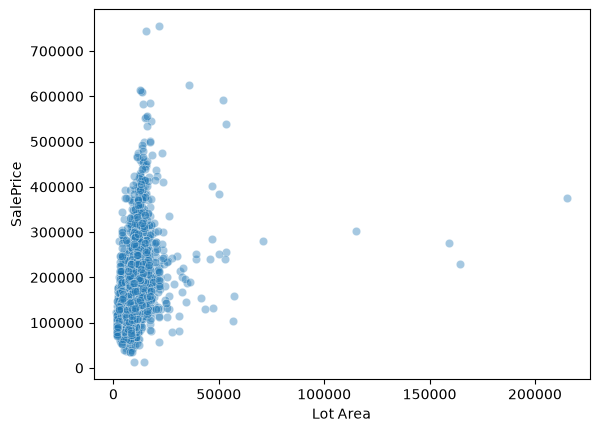

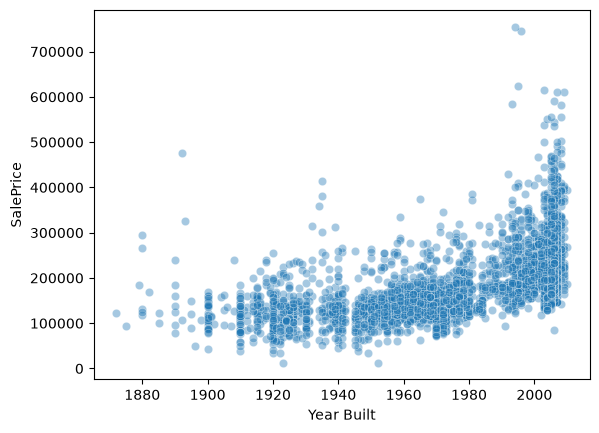

In [139]:
for c in ["Gr Liv Area", "Total Bsmt SF", "Lot Area", "Year Built"]:
    sns.scatterplot(data=df, x=c, y="SalePrice", alpha=0.4)
    plt.show()

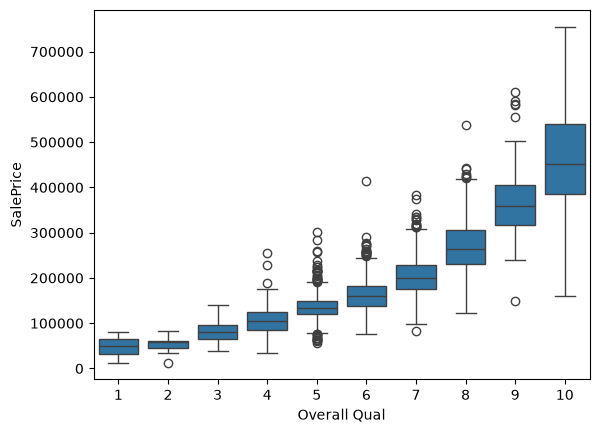

In [127]:
sns.boxplot(data=df, x="Overall Qual", y="SalePrice")
plt.show()

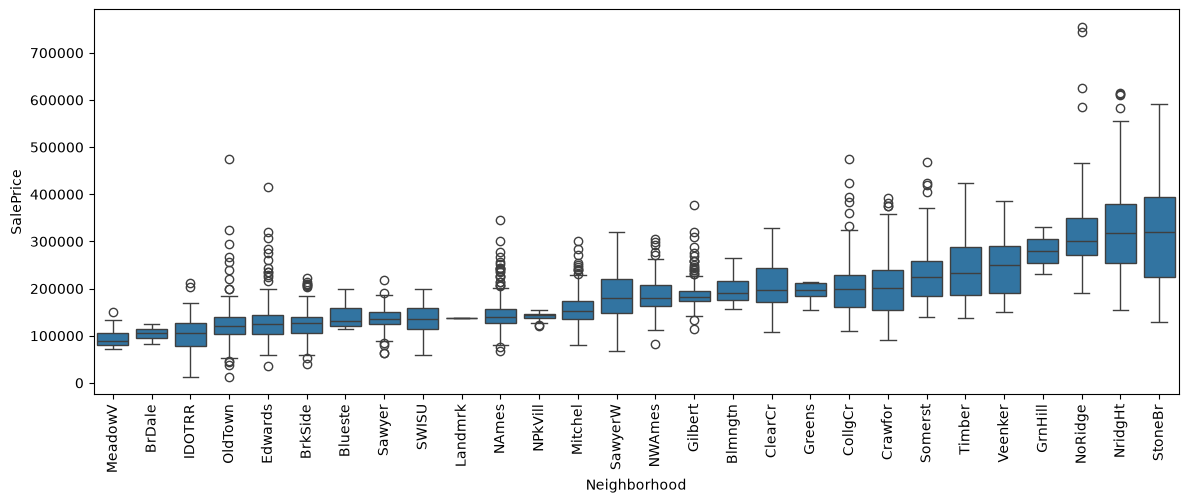

In [129]:
order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(14, 5))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=order)
plt.xticks(rotation=90)
plt.show()

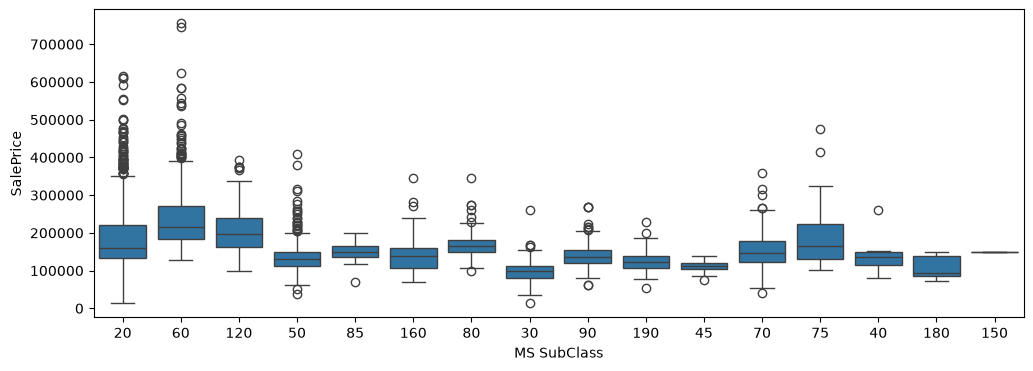

In [130]:
plt.figure(figsize=(12,4))
sns.boxplot(data=df, x="MS SubClass", y="SalePrice")
plt.show()

# Outlier

In [123]:
df[(df["Gr Liv Area"] > 4000)][["Gr Liv Area", "SalePrice", "Sale Condition"]]

,Gr Liv Area,SalePrice,Sale Condition
1498,5642,160000,Partial
1760,4476,745000,Abnorml
1767,4316,755000,Normal
2180,5095,183850,Partial
2181,4676,184750,Partial


# Feature Engineering

In [133]:
df["total_bath"] = df["Full Bath"] + 0.5*df["Half Bath"] + df["Bsmt Full Bath"].fillna(0) + 0.5*df["Bsmt Half Bath"].fillna(0)
df["renovated"] = (df["Year Remod/Add"] != df["Year Built"]).astype(int)
df["age_at_sale"] = df["Yr Sold"] - df["Year Built"]
df["since_remod"] = df["Yr Sold"] - df["Year Remod/Add"]

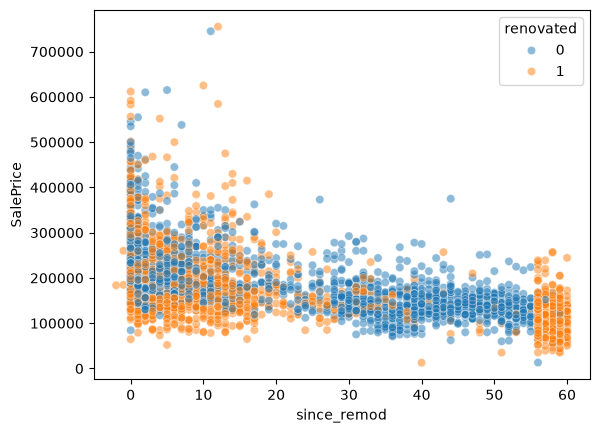

In [134]:
sns.scatterplot(data=df, x="since_remod", y="SalePrice", hue="renovated", alpha=0.5)
plt.show()

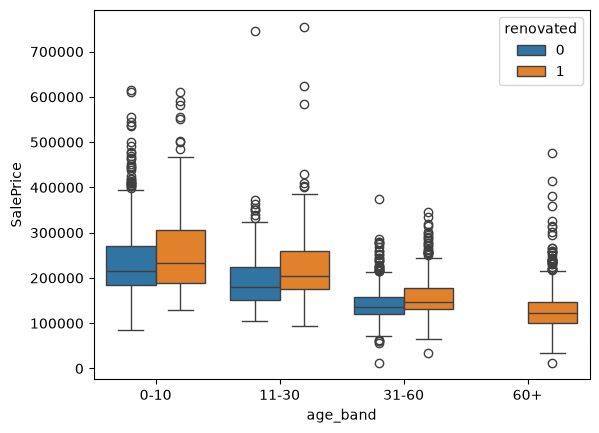

In [135]:
df["age_band"] = pd.cut(df["age_at_sale"], [-1, 10, 30, 60, 200], labels=["0-10", "11-30", "31-60", "60+"])
sns.boxplot(data=df, x="age_band", y="SalePrice", hue="renovated")
plt.show()


In [136]:
df.groupby("renovated")["age_at_sale"].median()

renovated
0    29.0
1    53.0
Name: age_at_sale, dtype: float64

# Multicollinearity

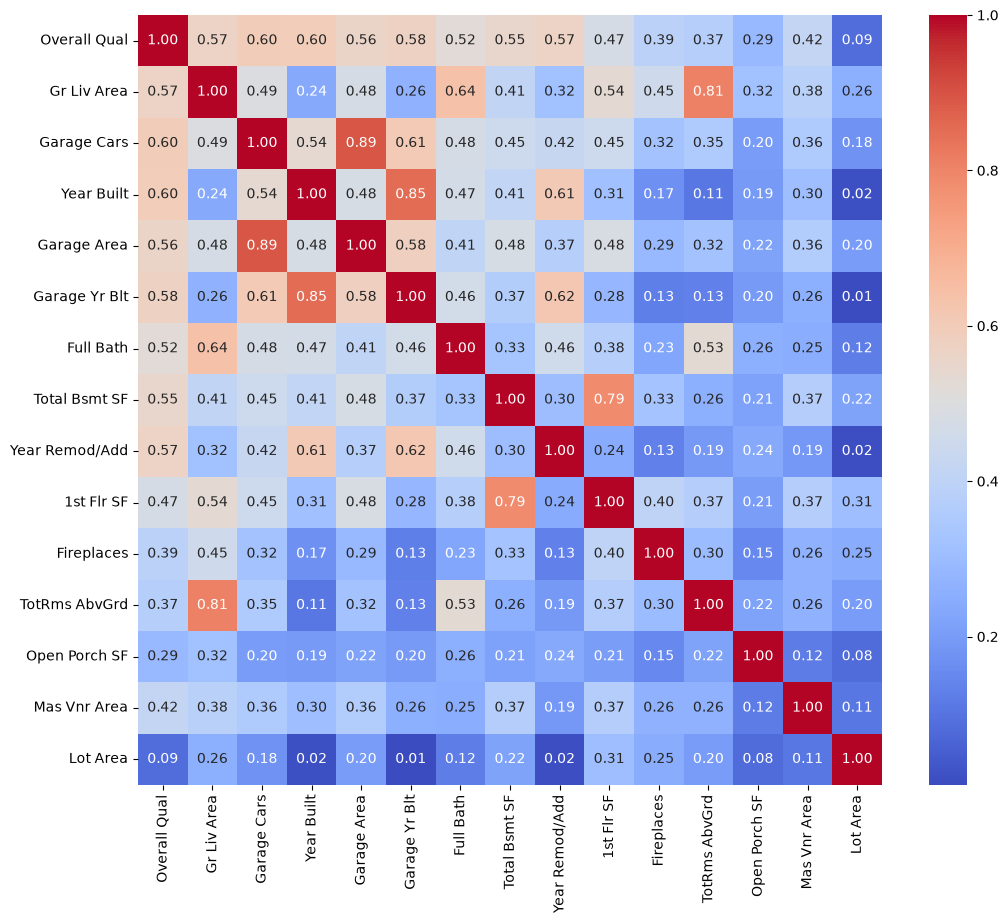

In [140]:
top = corr.drop("SalePrice").abs().sort_values(ascending=False).head(15).index
plt.figure(figsize=(12, 10))
sns.heatmap(df[top].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()